<a href="https://colab.research.google.com/github/kuzeynalcakar/tcga-cancer-gmm-clustering/blob/main/hellingerrna.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!unzip -o tcga-rna-datasets.zip -d tcga_rna
print("Ensured RNA data files are unzipped and available in 'tcga_rna' directory.")

unzip:  cannot find or open tcga-rna-datasets.zip, tcga-rna-datasets.zip.zip or tcga-rna-datasets.zip.ZIP.
Ensured RNA data files are unzipped and available in 'tcga_rna' directory.


In [ ]:
!kaggle datasets download -d tianjiechen/tcga-rna-datasets
!unzip -o tcga-rna-datasets.zip -d tcga_rna
print("downloaded and unzipped RNA data to 'tcga_rna' directory.")

Dataset URL: https://www.kaggle.com/datasets/tianjiechen/tcga-rna-datasets
License(s): MIT
tcga-rna-datasets.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  tcga-rna-datasets.zip
  inflating: tcga_rna/Liver RNA Data.csv  
  inflating: tcga_rna/Lung RNA Data.csv  
  inflating: tcga_rna/Prostate RNA Data.csv  
  inflating: tcga_rna/Thyroid RNA Data.csv  
downloaded and unzipped RNA data to 'tcga_rna' directory.


In [ ]:
from google.colab import files
files.upload()
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
print("Kaggle API credentials re-configured.")

Saving kaggle.json to kaggle (1).json
Kaggle API credentials re-configured.


In [ ]:
import pandas as pd

!kaggle datasets download -d tianjiechen/tcga-rna-datasets
!unzip -o tcga-rna-datasets.zip -d tcga_rna

# Load Liver RNA Data
liver_rna_df = pd.read_csv('tcga_rna/Liver RNA Data.csv')

# Load Lung RNA Data
lung_rna_df = pd.read_csv('tcga_rna/Lung RNA Data.csv')

# Load Prostate RNA Data
prostate_rna_df = pd.read_csv('tcga_rna/Prostate RNA Data.csv')

# Load Thyroid RNA Data
thyroid_rna_df = pd.read_csv('tcga_rna/Thyroid RNA Data.csv')

print("RNA data for Liver, Lung, Prostate, and Thyroid cancers loaded successfully into separate DataFrames.")

Dataset URL: https://www.kaggle.com/datasets/tianjiechen/tcga-rna-datasets
License(s): MIT
tcga-rna-datasets.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  tcga-rna-datasets.zip
  inflating: tcga_rna/Liver RNA Data.csv  
  inflating: tcga_rna/Lung RNA Data.csv  
  inflating: tcga_rna/Prostate RNA Data.csv  
  inflating: tcga_rna/Thyroid RNA Data.csv  
RNA data for Liver, Lung, Prostate, and Thyroid cancers loaded successfully into separate DataFrames.


Selected files:
 - Liver <- tcga_rna/Liver RNA Data.csv
 - Lung <- tcga_rna/Lung RNA Data.csv
 - Prostate <- tcga_rna/Prostate RNA Data.csv

Processing Liver
  raw shape (samples x genes): (20530, 422)
  after preprocessing: (20530, 422)
  chosen k (BIC): 6

Processing Lung
  raw shape (samples x genes): (20530, 1099)
  after preprocessing: (20530, 1099)
  chosen k (BIC): 6

Processing Prostate
  raw shape (samples x genes): (20530, 550)
  after preprocessing: (20530, 550)
  chosen k (BIC): 6


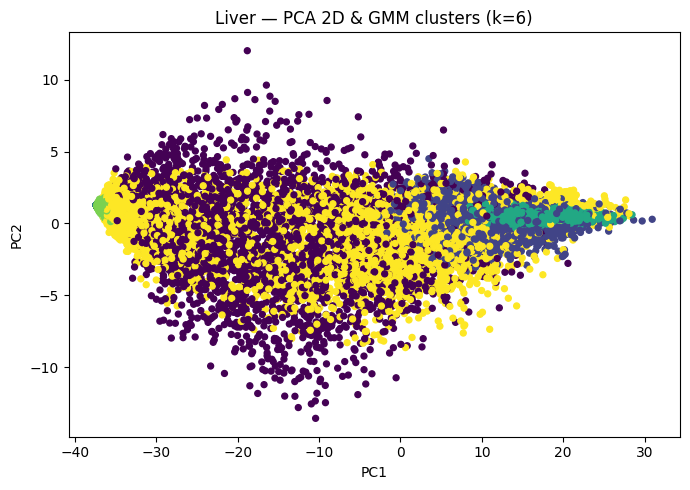

  saved gmm_hellinger_outputs/Liver_pca_gmm.png


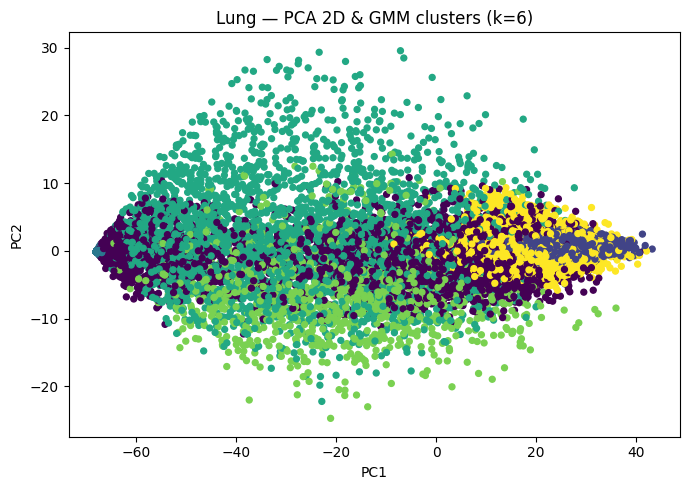

  saved gmm_hellinger_outputs/Lung_pca_gmm.png


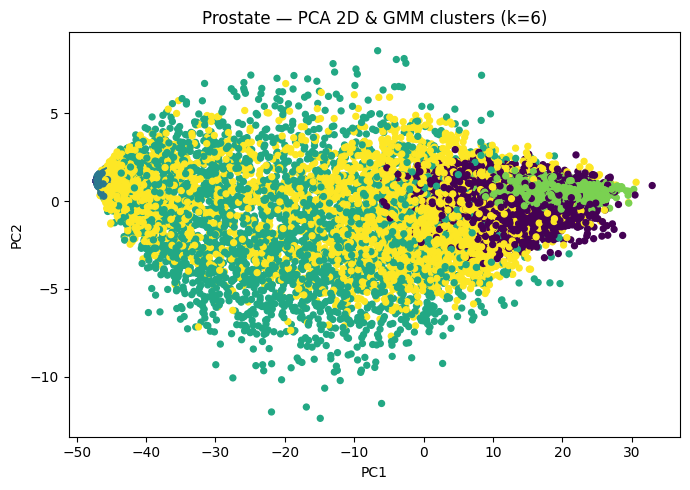

  saved gmm_hellinger_outputs/Prostate_pca_gmm.png


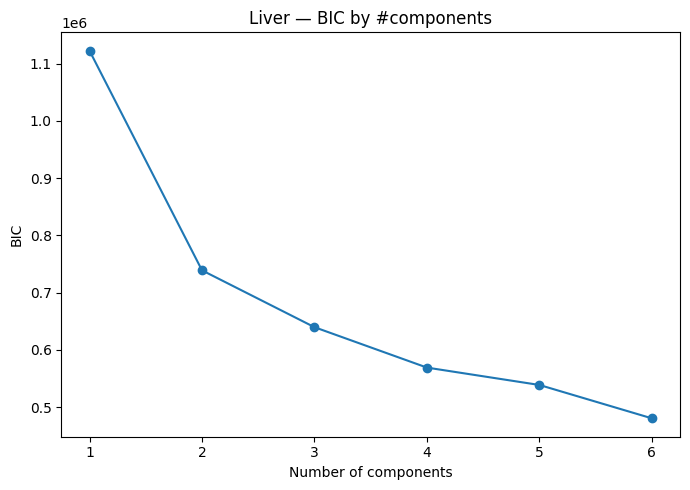

  saved gmm_hellinger_outputs/Liver_bic.png


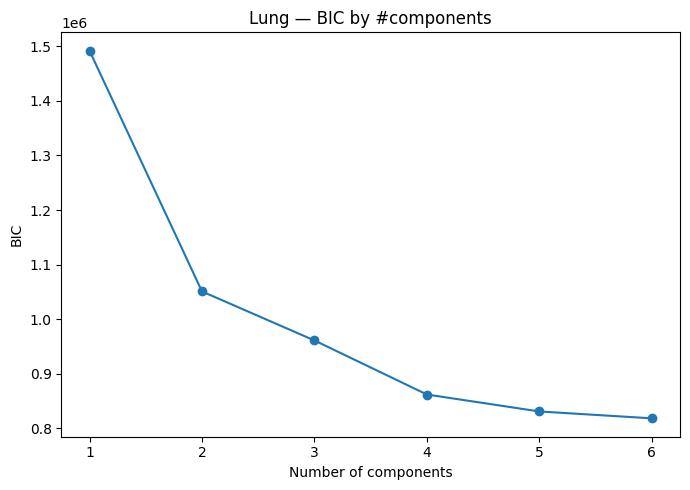

  saved gmm_hellinger_outputs/Lung_bic.png


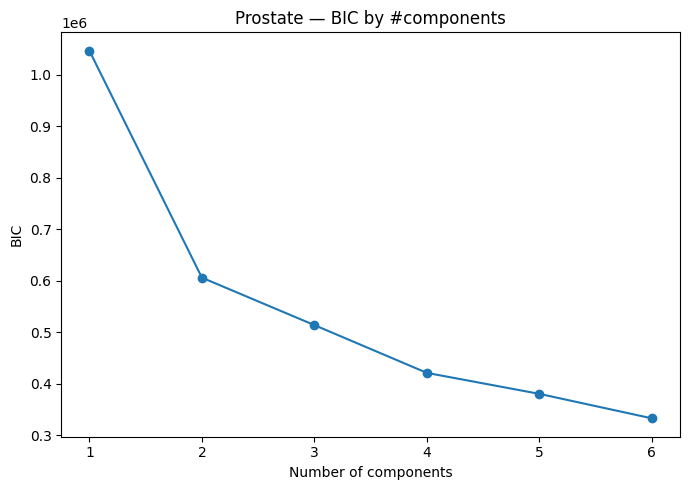

  saved gmm_hellinger_outputs/Prostate_bic.png


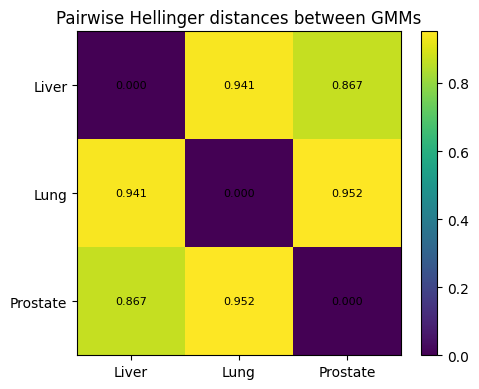

  saved gmm_hellinger_outputs/hellinger_heatmap.png


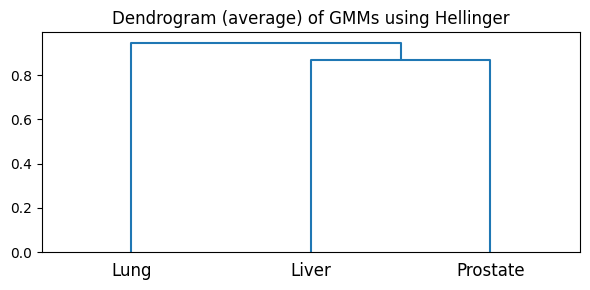

  saved gmm_hellinger_outputs/hellinger_dendrogram.png

Pairwise Hellinger distance matrix:
              Liver      Lung  Prostate
Liver     0.000000  0.940586  0.866766
Lung      0.940586  0.000000  0.951546
Prostate  0.866766  0.951546  0.000000

GMM summary:
     Dataset  Chosen_k  N_samples  N_PCA_dims
0     Liver         6      20530          20
1      Lung         6      20530          20
2  Prostate         6      20530          20

All figures saved into folder: gmm_hellinger_outputs


In [ ]:
import os, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from scipy.special import logsumexp
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

plt.rcParams['figure.figsize'] = (7,5)

DATA_DIR = "tcga_rna"   # CSV'lerin olduğu klasör
# Öncelikli arama isimleri (bulunursa bu üçü kullanılır)
PREFERRED = ["Liver", "Lung", "Prostate"]

# Parametreler
N_TOP_GENES = 2000
PCA_N = 20
HELLINGER_SAMPLES = 2000   # Monte Carlo örnek sayısı (hız/sağlamlık dengesi)
MAX_COMPONENTS = 6
RANDOM_STATE = 0

def find_csvs(data_dir=DATA_DIR):
    csvs = glob.glob(os.path.join(data_dir, "*.csv"))
    if not csvs:
        raise FileNotFoundError(f"No CSV files found in '{data_dir}'. Lütfen dosyaların orada olduğundan emin olun.")
    # Try to pick the preferred three (by name substring)
    selected = []
    for key in PREFERRED:
        for f in csvs:
            if key.lower() in os.path.basename(f).lower():
                selected.append((key, f))
                break
    if len(selected) < 3:
        # fallback: first 3 csvs, name from filename
        selected = [(os.path.splitext(os.path.basename(f))[0], f) for f in csvs[:3]]
    else:
        selected = selected[:3]
    return selected

def load_numeric_matrix(path):
    # Assumes first column is sample or gene id; read, keep numeric columns
    df = pd.read_csv(path, index_col=0)
    num = df.select_dtypes(include=[np.number])
    # If num has more columns than rows, probably genes x samples => transpose
    if num.shape[0] < num.shape[1]:
        num = num.T
    # Now num: rows = samples, cols = genes
    return num

def preprocess_expression(df, n_top_genes=N_TOP_GENES):
    df = df.dropna(axis=1, how='all')
    df = df.loc[:, (df != 0).any(axis=0)]
    X = np.log1p(df.values)               # log1p transform
    variances = np.var(X, axis=0)
    n_genes = min(n_top_genes, X.shape[1])
    top_idx = np.argsort(variances)[-n_genes:]
    X_sel = X[:, top_idx]
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_sel)
    return X_scaled, top_idx

def choose_gmm_via_bic(X, max_components=MAX_COMPONENTS, random_state=RANDOM_STATE):
    best_bic = np.inf
    best_gmm = None
    bics = []
    n_range = list(range(1, max_components+1))
    for n in n_range:
        gmm = GaussianMixture(n_components=n, covariance_type='full',
                              random_state=random_state, n_init=5)
        gmm.fit(X)
        bic = gmm.bic(X)
        bics.append(bic)
        if bic < best_bic:
            best_bic = bic
            best_gmm = gmm
    return best_gmm, n_range, bics

def hellinger_between_gmms(gmm_p, gmm_q, n_samples=HELLINGER_SAMPLES, random_state=RANDOM_STATE):
    n1 = n_samples // 2
    n2 = n_samples - n1
    X1, _ = gmm_p.sample(n1)
    X2, _ = gmm_q.sample(n2)
    X = np.vstack([X1, X2])
    logp = gmm_p.score_samples(X)
    logq = gmm_q.score_samples(X)
    logm = np.log(0.5) + logsumexp(np.vstack([logp, logq]), axis=0)
    log_sqrt_pq = 0.5 * (logp + logq)
    # np.errstate düzeltildi
    with np.errstate(over='ignore', invalid='ignore'):
        weights = np.exp(log_sqrt_pq - logm)
    S_est = np.mean(weights)
    S_est = float(np.clip(S_est, 0.0, 1.0))
    H = np.sqrt(max(0.0, 1.0 - S_est))
    return H, S_est

# Pipeline
selected = find_csvs(DATA_DIR)
print("Selected files:")
for name, path in selected:
    print(" -", name, "<-", path)

results = {}
for name, path in selected:
    print(f"\nProcessing {name}")
    mat = load_numeric_matrix(path)
    print("  raw shape (samples x genes):", mat.shape)
    X_scaled, top_idx = preprocess_expression(mat, n_top_genes=N_TOP_GENES)
    print("  after preprocessing:", X_scaled.shape)
    pca = PCA(n_components=min(PCA_N, X_scaled.shape[1], X_scaled.shape[0]-1))
    X_pca = pca.fit_transform(X_scaled)
    gmm, n_range, bics = choose_gmm_via_bic(X_pca, max_components=MAX_COMPONENTS)
    labels = gmm.predict(X_pca)
    results[name] = {
        "file": path, "raw_df": mat, "X_scaled": X_scaled, "pca": pca,
        "X_pca": X_pca, "gmm": gmm, "labels": labels, "bics": (n_range, bics)
    }
    print("  chosen k (BIC):", gmm.n_components)

names = list(results.keys())
m = len(names)
H = np.zeros((m,m))
Svals = np.zeros((m,m))
for i in range(m):
    for j in range(i, m):
        if i==j:
            H[i,j] = 0.0; Svals[i,j]=1.0
        else:
            gi = results[names[i]]["gmm"]
            gj = results[names[j]]["gmm"]
            h, s = hellinger_between_gmms(gi, gj, n_samples=HELLINGER_SAMPLES)
            H[i,j] = H[j,i] = h
            Svals[i,j] = Svals[j,i] = s

# Görseller + kaydet
outdir = "gmm_hellinger_outputs"
os.makedirs(outdir, exist_ok=True)

for name in names:
    Xp = results[name]["X_pca"]
    if Xp.shape[1] < 2:
        X2 = PCA(n_components=2).fit_transform(results[name]["X_scaled"])
    else:
        X2 = Xp[:,:2]
    labels = results[name]["labels"]
    plt.figure()
    plt.title(f"{name} — PCA 2D & GMM clusters (k={results[name]['gmm'].n_components})")
    plt.scatter(X2[:,0], X2[:,1], c=labels, s=18)
    plt.xlabel("PC1"); plt.ylabel("PC2")
    plt.tight_layout()
    fname = os.path.join(outdir, f"{name}_pca_gmm.png")
    plt.savefig(fname, dpi=150); plt.show()
    print("  saved", fname)

for name in names:
    n_range, bics = results[name]['bics']
    plt.figure()
    plt.plot(n_range, bics, marker='o')
    plt.title(f"{name} — BIC by #components")
    plt.xlabel("Number of components"); plt.ylabel("BIC")
    plt.tight_layout()
    fname = os.path.join(outdir, f"{name}_bic.png")
    plt.savefig(fname, dpi=150); plt.show()
    print("  saved", fname)

plt.figure(figsize=(5,4))
plt.title("Pairwise Hellinger distances between GMMs")
im = plt.imshow(H, interpolation='nearest')
plt.colorbar(im)
plt.xticks(range(m), names); plt.yticks(range(m), names)
for i in range(m):
    for j in range(m):
        plt.text(j, i, f"{H[i,j]:.3f}", ha='center', va='center', fontsize=8)
plt.tight_layout()
fname = os.path.join(outdir, "hellinger_heatmap.png")
plt.savefig(fname, dpi=150); plt.show()
print("  saved", fname)

condensed = squareform(H)
Z = linkage(condensed, method='average')
plt.figure(figsize=(6,3))
plt.title("Dendrogram (average) of GMMs using Hellinger")
dendrogram(Z, labels=names)
plt.tight_layout()
fname = os.path.join(outdir, "hellinger_dendrogram.png")
plt.savefig(fname, dpi=150); plt.show()
print("  saved", fname)

# Tablo çıktıları
dist_df = pd.DataFrame(H, index=names, columns=names)
summary = pd.DataFrame({
    "Dataset": names,
    "Chosen_k": [results[n]["gmm"].n_components for n in names],
    "N_samples": [results[n]["X_pca"].shape[0] for n in names],
    "N_PCA_dims": [results[n]["X_pca"].shape[1] for n in names],
})
print("\nPairwise Hellinger distance matrix:\n", dist_df)
print("\nGMM summary:\n", summary)
print(f"\nAll figures saved into folder: {outdir}")